# Section B


In [1]:
import os, math, time, random, copy, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
warnings.filterwarnings("ignore")

SMOKE      = os.environ.get("SMOKE") == "1"      # tiny dry-run switch (leave unset for the real run)
SEEDS      = [0, 1, 2]                           # reporting seeds
GRID_SEEDS = [100, 101]                          # seeds used only for hyper-parameter search
MAX_EPOCHS = 2 if SMOKE else 60
BATCH      = 50                                  # 400 / 50 = 8 iterations per epoch
DATA_SEED  = 1234                                # fixes the 500-image subset and the 400/100 split
SHIFT_SEED = 777                                 # fixes the corruption pipeline (shifted test set)
CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("device:", device, "| torch", torch.__version__, "| SMOKE:", SMOKE)

device: cpu | torch 2.14.1+cpu | SMOKE: False


## Data
 put provived files next to the notebook as `train_small.npz` and `shifted_test.npz` and they are used automatically. Otherwise the cell below re-creates a pipeline following the task text (rotation ±25°, brightness/contrast, ~25 % rectangular occlusion, blur, noise, and *my own guess* for the hidden corruption: random grayscale / channel swap on 50 % of images). The training code never imports or reuses these corruption parameters – the training augmentation is a separately written, differently parameterised pipeline.
Data setup and the hidden corruption. CIFAR-10 is loaded through `torchvision.datasets.CIFAR10`. `train_small` (50 images/class, seed 1234) is split 400 train / 100 validation (seed 1235), and neither test set is used for training, validation or tuning. The official hidden corruption was not available at the time of this submission. `shifted_test` was therefore re-created from the task text (rotation ±25°, brightness/contrast, ~25 % occlusion, plus blur and noise), and the hidden corruption is a **self-chosen assumption**: random grayscale or channel swap on 50 % of the images. All reported shifted-test numbers refer to this re-created set. To evaluate with the official hidden corruption, either place `train_small.npz` / `shifted_test.npz` next to the notebook (used automatically), or set `OFFICIAL_HIDDEN_FN` in the cell after E.4, and run all cells.

In [ ]:
def affine_batch(x, ang, scale, tx, ty, flip, padding="zeros"):
    # ang in degrees, scale>1 zooms in, tx/ty in normalised coords (2.0 == full width), flip = +1/-1
    a = ang * math.pi / 180; c, s = torch.cos(a), torch.sin(a); z = 1.0 / scale
    th = torch.zeros(x.shape[0], 2, 3, device=x.device)
    th[:,0,0] = z*c*flip; th[:,0,1] = -z*s; th[:,0,2] = tx
    th[:,1,0] = z*s*flip; th[:,1,1] =  z*c; th[:,1,2] = ty
    grid = F.affine_grid(th, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode=padding, align_corners=False)

def to_gray(x):
    return (0.299*x[:,0:1] + 0.587*x[:,1:2] + 0.114*x[:,2:3]).expand(-1,3,-1,-1)

def gauss_blur(x, sigma, k=5):                    
    B, C, H, W = x.shape
    r = torch.arange(k, device=x.device).float() - k//2
    k1 = torch.exp(-(r.view(1,-1)**2) / (2*sigma.view(B,1)**2)); k1 = k1 / k1.sum(1, keepdim=True)
    ker = (k1.unsqueeze(2) * k1.unsqueeze(1)).repeat_interleave(C, 0).unsqueeze(1)
    out = F.conv2d(F.pad(x.reshape(1,B*C,H,W), (k//2,)*4, mode="reflect"), ker, groups=B*C)
    return out.reshape(B, C, H, W)

def rect_mask(B, H, W, h, w, cy, cx, dev):          # True inside each sample's rectangle
    ys = torch.arange(H, device=dev).view(1,H,1) + .5; xs = torch.arange(W, device=dev).view(1,1,W) + .5
    return ((ys - cy.view(B,1,1)).abs() < h.view(B,1,1)/2) & ((xs - cx.view(B,1,1)).abs() < w.view(B,1,1)/2)

PERMS = torch.tensor([[0,1,2],[0,2,1],[1,0,2],[1,2,0],[2,0,1],[2,1,0]])
def channel_permute(x, k):                        
    idx = PERMS.to(x.device)[k]
    return torch.gather(x, 1, idx[:,:,None,None].expand(-1,-1,x.shape[2],x.shape[3]))

def make_shifted(x, seed, hidden=True):
    # hidden=False -> only the corruptions listed in the task (used for the validation proxy)
    g = torch.Generator().manual_seed(seed); B, _, H, W = x.shape
    U = lambda lo, hi, *sh: lo + (hi-lo)*torch.rand(*sh, generator=g)
    ang = U(-25, 25, B)
    out = affine_batch(x, ang, torch.ones(B), torch.zeros(B), torch.zeros(B), torch.ones(B), "zeros")
    bf, cf = U(.5, 1.5, B,1,1,1), U(.6, 1.4, B,1,1,1)                       # brightness / contrast
    out = out * bf; m = out.mean((1,2,3), keepdim=True); out = ((out - m)*cf + m).clamp(0,1)
    blur = torch.rand(B, generator=g) < .5                              
    out = gauss_blur(out, torch.where(blur, U(.6,1.5,B), torch.full((B,), .05)))
    noisy = torch.rand(B, generator=g) < .5                                  
    sd = U(.03, .10, B) * noisy
    out = (out + torch.randn(out.shape, generator=g) * sd.view(B,1,1,1)).clamp(0,1)
    af, ar = U(.20,.30,B), torch.exp(U(-.35,.35,B))                      
    h = torch.sqrt(af*H*W*ar).clamp(max=H); w = torch.sqrt(af*H*W/ar).clamp(max=W)
    cy = h/2 + torch.rand(B, generator=g)*(H-h); cx = w/2 + torch.rand(B, generator=g)*(W-w)
    out = out.masked_fill(rect_mask(B,H,W,h,w,cy,cx,out.device).unsqueeze(1), 0.)
    hid = torch.zeros(B, dtype=torch.long)
    if hidden:                                                           
        hid = torch.where(torch.rand(B, generator=g) < .5, torch.randint(1,3,(B,), generator=g), hid)
        out = torch.where((hid==1).view(B,1,1,1), to_gray(out), out)
        sw  = channel_permute(out, torch.randint(1,6,(B,), generator=g))     
        out = torch.where((hid==2).view(B,1,1,1), sw, out)
    meta = dict(angle=ang.numpy(), bright=bf.flatten().numpy(), contrast=cf.flatten().numpy(),
                blur=blur.numpy(), noise=sd.numpy(), occ=(af).numpy(), hidden=hid.numpy())
    return out.clamp(0,1), meta

In [ ]:
import torchvision
def fake_cifar(n_tr, n_te, seed=0):                                
    g = np.random.RandomState(seed)
    return (g.randint(0,256,(n_tr,32,32,3),dtype=np.uint8), g.randint(0,10,n_tr),
            g.randint(0,256,(n_te,32,32,3),dtype=np.uint8), g.randint(0,10,n_te))

def to_t(a): return torch.from_numpy(a).permute(0,3,1,2).float().div(255)

if SMOKE:
    xtr_all, ytr_all, xte, yte = fake_cifar(5000, 600)
else:
    tr = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
    te = torchvision.datasets.CIFAR10("./data", train=False, download=True)
    xtr_all, ytr_all, xte, yte = tr.data, np.array(tr.targets), te.data, np.array(te.targets)

if os.path.exists("train_small.npz"):
    d = np.load("train_small.npz"); xs, ys = d["x"], d["y"]
else:
    rs = np.random.RandomState(DATA_SEED)
    idx = np.concatenate([rs.choice(np.where(ytr_all==c)[0], 50, replace=False) for c in range(10)])
    xs, ys = xtr_all[idx], ytr_all[idx]
rs = np.random.RandomState(DATA_SEED + 1)
tr_i, va_i = [], []
for c in range(10):
    ci = rs.permutation(np.where(ys==c)[0]); tr_i += list(ci[:40]); va_i += list(ci[40:])
x_tr, y_tr = to_t(xs[tr_i]).to(device), torch.tensor(ys[tr_i]).to(device)
x_va, y_va = to_t(xs[va_i]).to(device), torch.tensor(ys[va_i]).to(device)

x_clean, y_test = to_t(xte), torch.tensor(yte)
if os.path.exists("shifted_test.npz"):
    d = np.load("shifted_test.npz"); x_shift = to_t(d["x"]); meta = None; print("using OFFICIAL shifted_test.npz")
else:
    x_shift, meta = make_shifted(x_clean, SHIFT_SEED, hidden=True)
x_clean, x_shift, y_test = x_clean.to(device), x_shift.to(device), y_test.to(device)

x_va_shift = make_shifted(x_va.cpu(), SHIFT_SEED + 1, hidden=False)[0].to(device)

print("train", tuple(x_tr.shape), "val", tuple(x_va.shape), "| class counts train:",
      torch.bincount(y_tr).tolist(), "val:", torch.bincount(y_va).tolist())
print("clean_test", tuple(x_clean.shape), "shifted_test", tuple(x_shift.shape))

train (400, 3, 32, 32) val (100, 3, 32, 32) | class counts train: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40] val: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
clean_test (10000, 3, 32, 32) shifted_test (10000, 3, 32, 32)


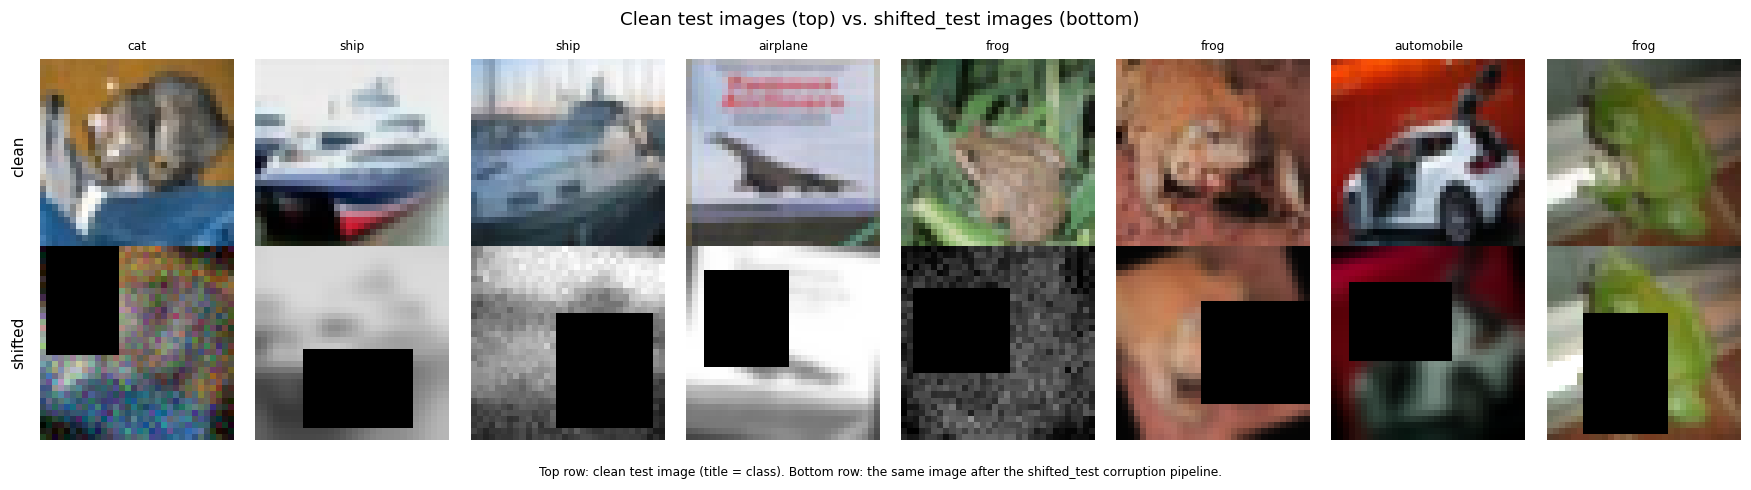

In [4]:
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for j in range(8):
    ax[0,j].imshow(x_clean[j].permute(1,2,0).cpu()); ax[0,j].set_title(CLASSES[y_test[j]], fontsize=8); ax[0,j].axis("off")
    ax[1,j].imshow(x_shift[j].permute(1,2,0).cpu()); ax[1,j].axis("off")
ax[0,0].text(-.15,.5,"clean",transform=ax[0,0].transAxes,rotation=90,va="center"); ax[1,0].text(-.15,.5,"shifted",transform=ax[1,0].transAxes,rotation=90,va="center")
fig.suptitle("Clean test images (top) vs. shifted_test images (bottom)"); fig.legend(handles=[Patch(color="none", label="Top row: clean test image (title = class). Bottom row: the same image after the shifted_test corruption pipeline.")], loc="lower center", frameon=False, handlelength=0, fontsize=8); plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()

## 1. Model: small Inception network

In [5]:
def cbr(cin, cout, k):
    return nn.Sequential(nn.Conv2d(cin, cout, k, padding=k//2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Inception(nn.Module):
    def __init__(s, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        s.b1 = cbr(cin, c1, 1)
        s.b2 = nn.Sequential(cbr(cin, c3r, 1), cbr(c3r, c3, 3))
        s.b3 = nn.Sequential(cbr(cin, c5r, 1), cbr(c5r, c5, 5))
        s.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(cin, cp, 1))
        s.out = c1 + c3 + c5 + cp
    def forward(s, x): return torch.cat([s.b1(x), s.b2(x), s.b3(x), s.b4(x)], 1)

class InceptionNet(nn.Module):
    def __init__(s, drop=0.0):
        super().__init__()
        s.register_buffer("mu",  torch.tensor([0.4914,0.4822,0.4465]).view(1,3,1,1))
        s.register_buffer("std", torch.tensor([0.2470,0.2435,0.2616]).view(1,3,1,1))
        s.stem = cbr(3, 32, 3)
        s.i1 = Inception(32, 16, 16, 32,  8, 8, 8)
        s.i2 = Inception(s.i1.out, 32, 32, 48, 8, 16, 16)
        s.i3 = Inception(s.i2.out, 48, 48, 96, 16, 32, 32)
        s.pool = nn.MaxPool2d(2)
        s.drop = nn.Dropout(drop)
        s.fc = nn.Linear(s.i3.out, 10)
    def forward(s, x):
        x = (x - s.mu) / s.std
        x = s.pool(s.stem(x)); x = s.pool(s.i1(x)); x = s.pool(s.i2(x)); x = s.i3(x)
        return s.fc(s.drop(x.mean((2,3))))

n_params = sum(p.numel() for p in InceptionNet().parameters() if p.requires_grad)
assert n_params <= 1_000_000, n_params
print(f"trainable parameters: {n_params:,}  (limit 1,000,000)")

trainable parameters: 104,842  (limit 1,000,000)


## 2. Augmentation toolbox

All operations are vectorised on a mini-batch and are re-sampled **every time an image is seen**.


Rotation range is deliberately a bit wider (±30°) than the ±25° quoted for the test, because the exact test pipeline must not be copied and a small safety margin costs little.

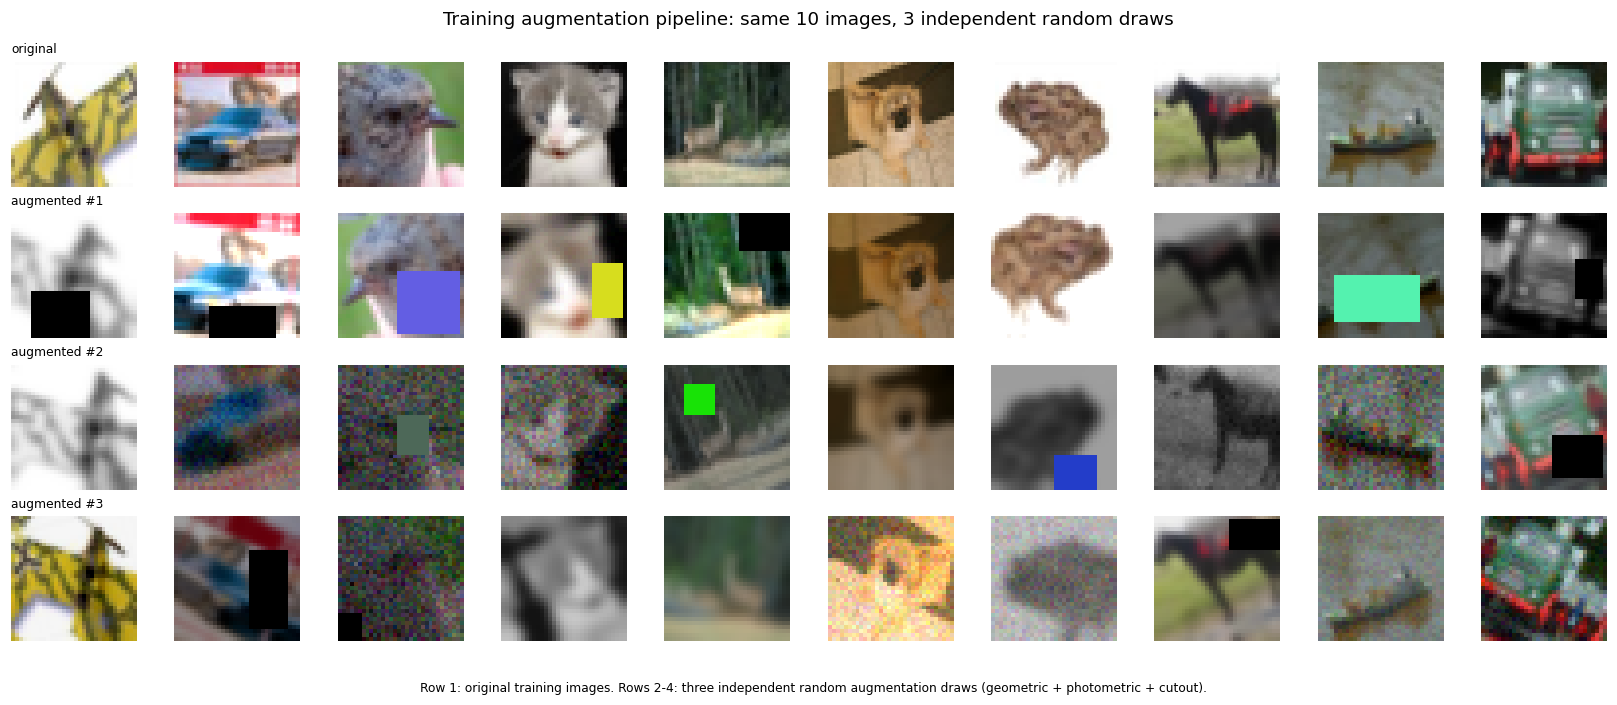

In [ ]:
def aug_geometric(x, rot=30., scale=(.85,1.15), shift_px=4, flip=True):
    B, d = x.shape[0], x.device
    R = lambda lo, hi: lo + (hi-lo)*torch.rand(B, device=d)
    f = torch.where(torch.rand(B, device=d) < .5, -1., 1.) if flip else torch.ones(B, device=d)
    t = shift_px * 2 / x.shape[-1]
    return affine_batch(x, R(-rot, rot), R(*scale), R(-t, t), R(-t, t), f, padding="reflection")

def aug_photometric(x, chan_perm=False):
    B, d = x.shape[0], x.device
    R = lambda lo, hi: lo + (hi-lo)*torch.rand(B,1,1,1, device=d)
    x = x * R(.5, 1.5)
    m = x.mean((1,2,3), keepdim=True); x = (x - m) * R(.6, 1.4) + m
    g = to_gray(x); x = (x - g) * R(.2, 1.6) + g
    sig = torch.where(torch.rand(B, device=d) < .3, R(.3, 1.5).flatten(), torch.full((B,), .05, device=d))
    x = gauss_blur(x.clamp(0,1), sig)
    x = x + torch.randn_like(x) * R(0, .08) * (torch.rand(B,1,1,1, device=d) < .4)
    x = torch.where(torch.rand(B,1,1,1, device=d) < .15, to_gray(x), x)
    if chan_perm:                                               # off by default
        x = torch.where(torch.rand(B,1,1,1, device=d) < .1, channel_permute(x, torch.randint(0,6,(B,), device=d)), x)
    return x.clamp(0, 1)

def aug_cutout(x, p=.5, area=(.05,.30)):
    B, _, H, W = x.shape; d = x.device
    af = area[0] + (area[1]-area[0]) * torch.rand(B, device=d)
    r = torch.exp((torch.rand(B, device=d)*2-1) * math.log(2))
    h = torch.sqrt(af*H*W*r).clamp(max=H); w = torch.sqrt(af*H*W/r).clamp(max=W)
    m = rect_mask(B, H, W, h, w, torch.rand(B, device=d)*H, torch.rand(B, device=d)*W, d)
    m = m & (torch.rand(B, device=d) < p).view(B,1,1)
    fill = torch.rand(B,3,1,1, device=d) * (torch.rand(B,1,1,1, device=d) < .5)      
    return torch.where(m.unsqueeze(1), fill.expand_as(x), x)

def mix_batch(x, ysoft, mode, alpha=1.0):
    B, _, H, W = x.shape; lam = float(np.random.beta(alpha, alpha)); perm = torch.randperm(B, device=x.device)
    if mode == "mixup":
        x = lam * x + (1-lam) * x[perm]
    else:                                                       # cutmix
        r = math.sqrt(1-lam); h, w = int(H*r), int(W*r); cy, cx = np.random.randint(H), np.random.randint(W)
        y0, y1, x0, x1 = max(cy-h//2,0), min(cy+h//2,H), max(cx-w//2,0), min(cx+w//2,W)
        x = x.clone(); x[:,:,y0:y1,x0:x1] = x[perm][:,:,y0:y1,x0:x1]
        lam = 1 - (y1-y0)*(x1-x0)/(H*W)
    return x, lam*ysoft + (1-lam)*ysoft[perm]

def augment(x, cfg):
    if cfg.get("geo"):    x = aug_geometric(x, rot=cfg.get("rot", 30.))
    if cfg.get("photo"):  x = aug_photometric(x, cfg.get("chan_perm", False))
    if cfg.get("cutout"): x = aug_cutout(x, p=cfg.get("cutout_p", .5))
    return x

# quick visual check of the pipeline
cfg_demo = dict(geo=True, photo=True, cutout=True)
seed_everything(0); xb = x_tr[::40][:10]
fig, ax = plt.subplots(4, 10, figsize=(15, 6.4))
for r in range(4):
    xa = xb if r == 0 else augment(xb, cfg_demo)
    for j in range(10):
        ax[r,j].imshow(xa[j].permute(1,2,0).cpu()); ax[r,j].axis("off")
    ax[r,0].set_title("original" if r==0 else f"augmented #{r}", fontsize=8, loc="left")
fig.suptitle("Training augmentation pipeline: same 10 images, 3 independent random draws"); fig.legend(handles=[Patch(color="none", label="Row 1: original training images. Rows 2-4: three independent random augmentation draws (geometric + photometric + cutout).")], loc="lower center", frameon=False, handlelength=0, fontsize=8); plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()

## 3. Training and evaluation engine

* Optimiser AdamW , batch 50, linear warm-up (3 epochs) + cosine decay, max 60 epochs.
* Loss = soft-target cross-entropy (supports Mixup/CutMix and label smoothing).
* Early stopping uses *validation only*: score = ½(clean-val acc + val-proxy-shift acc); the best-scoring epoch's weights are restored. `patience` stops the run if the score has not improved for that many epochs.
* "Train acc" is measured on the clean 400 training images in eval mode (no augmentation, no dropout), so it is comparable across configurations.

In [7]:
@torch.no_grad()
def logits_of(model, X, bs=1000):
    model.eval(); return torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)])

def acc_of(model, X, Y): return (logits_of(model, X).argmax(1) == Y).float().mean().item()

def soft_ce(logits, target): return -(target * F.log_softmax(logits, 1)).sum(1).mean()

def run(cfg, seed, lr=2e-3, wd=2e-2, epochs=MAX_EPOCHS, patience=20, eval_test=False, keep_model=False):
    seed_everything(seed)
    model = InceptionNet(drop=cfg.get("drop", 0.)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps_ep = len(x_tr) // BATCH; total = epochs * steps_ep; warm = 3 * steps_ep
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: (t+1)/warm if t < warm else
                                              .5*(1+math.cos(math.pi*(t-warm)/max(1,total-warm))))
    ls = cfg.get("ls", 0.); H = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], vs_acc=[])
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(x_tr), device=device); run_loss = 0.
        for i in range(steps_ep):
            b = perm[i*BATCH:(i+1)*BATCH]; xb, yb = x_tr[b], y_tr[b]
            ys = F.one_hot(yb, 10).float() * (1-ls) + ls/10
            xb = augment(xb, cfg)
            if cfg.get("mix") and np.random.rand() < cfg.get("mix_p", .7):
                xb, ys = mix_batch(xb, ys, cfg["mix"], cfg.get("mix_alpha", 1.0))
            loss = soft_ce(model(xb), ys)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run_loss += loss.item()
        lv = logits_of(model, x_va)
        H["train_loss"].append(run_loss/steps_ep); H["train_acc"].append(acc_of(model, x_tr, y_tr))
        H["val_loss"].append(F.cross_entropy(lv, y_va).item()); H["val_acc"].append((lv.argmax(1)==y_va).float().mean().item())
        H["vs_acc"].append(acc_of(model, x_va_shift, y_va))
        score = .5 * (H["val_acc"][-1] + H["vs_acc"][-1])
        if score > best: best, bad, best_ep = score, 0, ep; best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience and bad >= patience: break
    model.load_state_dict(best_state)
    res = dict(hist=H, best_ep=best_ep, train=acc_of(model, x_tr, y_tr), val=acc_of(model, x_va, y_va),
               val_shift=acc_of(model, x_va_shift, y_va))
    if eval_test:                                              # test data touched here only, for final reporting
        res["clean"] = acc_of(model, x_clean, y_test); res["shifted"] = acc_of(model, x_shift, y_test)
    if keep_model: res["model"] = model
    return res

def agg(results, key):
    v = np.array([r[key] for r in results]) * 100; return v.mean(), v.std()
fmt = lambda results, key: "%.2f ± %.2f" % agg(results, key)
t0 = time.time(); _ = run(dict(), 0, epochs=2); print(f"sanity run (2 epochs): {time.time()-t0:.1f}s")

sanity run (2 epochs): 8.5s


## Part A – Baseline (no augmentation, no regularisation)

Plain network: no augmentation, **no dropout, no weight decay, no label smoothing**, no early stopping (all 60 epochs are run so the over-fitting is visible; the reported weights are the best-validation epoch). 3 seeds.

In [8]:
cfg_base = dict()                                                      # nothing at all
base_runs = [run(cfg_base, s, wd=0., patience=None, eval_test=True) for s in SEEDS]
print("BASELINE (mean ± std over seeds %s)" % SEEDS)
for k, n in [("train","Train acc (clean 400)"),("val","Val acc (clean 100)"),("clean","Clean-test acc"),("shifted","Shifted-test acc")]:
    print(f"  {n:24s}: {fmt(base_runs, k)} %")

BASELINE (mean ± std over seeds [0, 1, 2])
  Train acc (clean 400)   : 100.00 ± 0.00 %
  Val acc (clean 100)     : 46.67 ± 4.78 %
  Clean-test acc          : 41.59 ± 0.66 %
  Shifted-test acc        : 14.21 ± 0.33 %


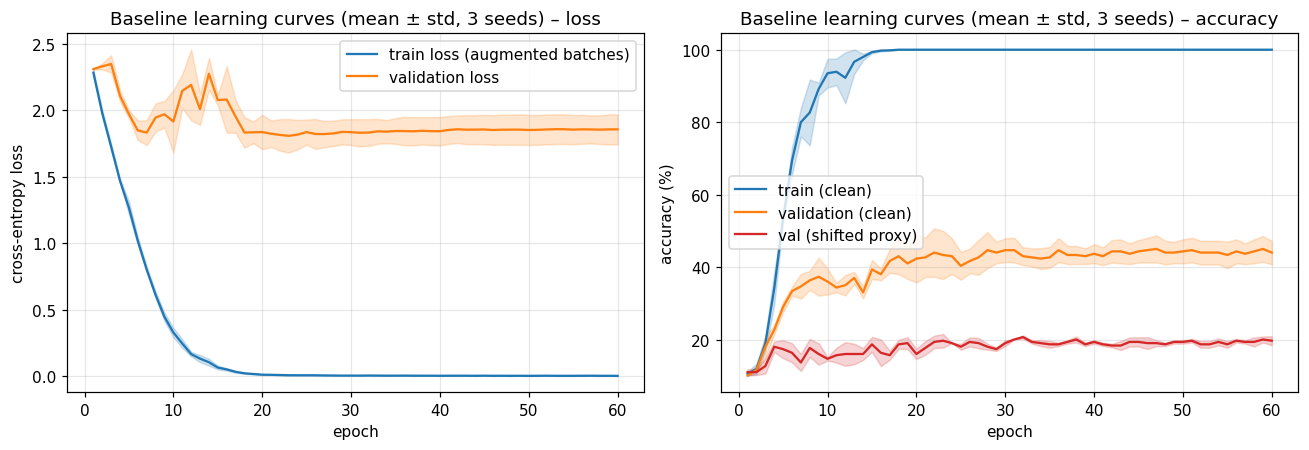

In [9]:
def curves(runs, title, fname=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for key, lab, col in [("train","train (clean)", "C0"), ("val","validation (clean)", "C1"), ("vs","val (shifted proxy)", "C3")]:
        for a, suffix in [(ax[1], "_acc")]:
            L = min(len(r["hist"][key+suffix]) for r in runs); A = np.array([r["hist"][key+suffix][:L] for r in runs]) * 100
            e = np.arange(1, L+1); a.plot(e, A.mean(0), color=col, label=lab); a.fill_between(e, A.mean(0)-A.std(0), A.mean(0)+A.std(0), color=col, alpha=.2)
    for key, lab, col in [("train_loss","train loss (augmented batches)","C0"), ("val_loss","validation loss","C1")]:
        L = min(len(r["hist"][key]) for r in runs); A = np.array([r["hist"][key][:L] for r in runs]); e = np.arange(1, L+1)
        ax[0].plot(e, A.mean(0), color=col, label=lab); ax[0].fill_between(e, A.mean(0)-A.std(0), A.mean(0)+A.std(0), color=col, alpha=.2)
    ax[0].set(xlabel="epoch", ylabel="cross-entropy loss", title=title+" – loss"); ax[0].legend()
    ax[1].set(xlabel="epoch", ylabel="accuracy (%)", title=title+" – accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()
curves(base_runs, "Baseline learning curves (mean ± std, 3 seeds)")

In [10]:
m = lambda k: agg(base_runs, k)[0]
print(f"train→val gap         : {m('train')-m('val'):6.2f} pts   (over-fitting: train {m('train'):.1f}% vs val {m('val'):.1f}%)")
print(f"clean-test→shifted gap: {m('clean')-m('shifted'):6.2f} pts   (covariate shift: clean {m('clean'):.1f}% vs shifted {m('shifted'):.1f}%)")

train→val gap         :  53.33 pts   (over-fitting: train 100.0% vs val 46.7%)
clean-test→shifted gap:  27.38 pts   (covariate shift: clean 41.6% vs shifted 14.2%)


 Baseline (3 seeds): train 100.00 ± 0.00 %, validation 46.67 ± 4.78 %, clean test 41.59 ± 0.66 %, shifted test 14.21 ± 0.33 % (chance = 10 %). The train→val gap is 53.3 pts and the clean→shifted gap is 27.4 pts (both printed above).

*Overfitting.* Training accuracy reaches 100 % by about epoch 16 and the training loss is ≈ 0 by about epoch 20, while validation accuracy stays at ≈ 43-45 % and the shifted-validation proxy at ≈ 19-20 % until epoch 60. The network memorises the 400 images in about a quarter of the budget and then learns nothing more. The validation loss does not climb steadily: it reaches ≈ 1.83 near epoch 7, spikes to ≈ 2.3 around epochs 12-14 (large seed variation) and then stays flat at ≈ 1.85, far above the ≈ 0 training loss. That is a memorised, over-confident classifier, but "validation loss bottoms out early and then climbs" is not what the plot shows.

*Covariate shift.* Labels are unchanged, but the input distribution now contains rotation, brightness/contrast changes, blur, noise, a black occluder and gray or channel-swapped colours that never occur in the 400 training images. Shifted accuracy of 14.2 % is only 4.2 pts above chance, so the baseline has learned essentially no invariance to any of them.

*Verdict: both.* Overfitting caps clean accuracy at ≈ 42 %, and the missing invariances remove another ≈ 27 pts. Regularisation alone does not fix the second problem: the regularised "No augmentation" row of Part D reaches 14.72 ± 0.13 % on the shifted test (the same as the plain baseline within noise) and 42.40 ± 2.03 % clean.

## Part B Augmentation strategy: design and justification

**Chosen augmentations:** geometric (rotation, scale, translation/crop, horizontal flip), photometric (brightness, contrast, saturation, blur, noise, random grayscale), Cutout / Random Erasing, and Mixup or CutMix with label smoothing. Each family maps to a concrete nuisance factor of the shifted test (rotation ↔ geometric; brightness/contrast/blur/noise ↔ photometric; occlusion ↔ Cutout), plus random grayscale as a *generic* colour-invariance prior that also guards against an unknown colour corruption. Mixup/CutMix is a pure regulariser (it does not mimic a specific corruption).

**Q1 – Would vertical flip help or hurt?** It would **hurt (or at best not help)**. Horizontal flip preserves semantics (a mirrored horse is still a horse), but CIFAR-10 objects have a strong canonical vertical layout: sky above, ground below, wheels at the bottom, trucks and ships upright. Upside-down images are never in the test set (rotation is only ±25°), so the model would spend its tiny capacity on a pose it will never see, and it blurs cues like "sky/horizon on top" that help to separate airplane/bird/ship from frog/deer/horse. It also adds invariance to a transform that, unlike horizontal flip, does not occur in natural photographs.

**Q2 – Rotation to ±90° when test is ±25°.** *Benefit:* the ±25° range is fully covered with margin and the model becomes tolerant to unexpected stronger tilts. *Cost:* only ~28 % of the sampled angles are in the useful range, so most gradient steps are spent on poses that never occur at test time (**train/test mismatch**); the model must devote capacity to larger invariances, the in-range accuracy drops, bilinear-interpolation blur and corner fill artefacts become larger, and with 400 images the effective "clean" signal is diluted. Best practice is to match the augmentation range to the expected nuisance range with a modest margin (here ±30° vs. ±25°).

**Q3 – Why too much augmentation can reduce accuracy on a small model.** A model with ~0.15 M parameters has limited capacity. Strong, stacked augmentations (heavy occlusion + Mixup + noise + rotation) make the training distribution much *harder* than the data the model will see, so it **under-fits**: it must spend capacity on explaining the corruptions instead of the objects, label information is destroyed (an occluded or mixed image may not contain the object any more → label noise), and train/test distribution mismatch grows (e.g. BatchNorm statistics are computed on heavily distorted images but used on milder ones). Augmentation is regularisation; beyond the point where training accuracy on the augmented data stops improving, extra strength adds bias faster than it removes variance. This is why the strengths are chosen on validation data (below) and why the ablation adds one family at a time.

**Evidence from this notebook for Q1-Q3.** The answers above are arguments only: no vertical-flip, ±90° or over-augmentation experiment was run, so none of the three is backed by numbers of its own. The only related observation is in Part D: geometric-only augmentation (rotation ±30°, scale, shift, h-flip) did not improve the shifted test (14.68 vs 14.72 %) and lowered clean accuracy (42.40 → 40.35 %), which is consistent with the Q3 warning that augmentation costs capacity on a small model but does not test it. If your instructor expects empirical support, add two rows (geometric + vertical flip, and rotation ±90°) and quote them.

## Part C  Regularisation and training design 

**BatchNorm** is placed after every convolution, before the ReLU. It normalises activations, which gives stable high learning rates and a mild noise-injection regularisation effect with batch size 50, and it keeps the outputs of the 5×5, 3×3 and 1×1 branches on the same scale before they are concatenated.

**Dropout** (p = 0.3) is placed only after global average pooling, before the FC layer. The FC classifier on the pooled feature is where co-adaptation of features is easiest and where memorisation happens. Convolutional feature maps are spatially correlated, so dropping single activations in the early convolutions removes almost no information (neighbouring activations carry it) while disturbing the low-level filters that the whole network depends on.

**Weight decay** uses AdamW with a value selected on validation data (0.01 in this run), applied to all weights. Decoupled decay shrinks the weights independently of the adaptive step size and limits the effective capacity of the network.

**Label smoothing** (0.05–0.2 searched on validation, 0.2 selected) is used together with Mixup/CutMix. It prevents over-confident logits when training on only 400 images, improves calibration and complements the soft mixed targets.

**The learning-rate schedule** is a 3-epoch linear warm-up followed by cosine decay to 0. The warm-up avoids early BatchNorm/Adam instability, and the small final learning rate of the cosine schedule lets the model settle into a flat minimum.

**Early stopping** restores the best-validation epoch (patience 20; it is not used in the baseline). It is validation-only model selection and protects against the late-epoch overfitting visible in Part A.

**A global-average-pooling head** replaces large FC layers. This removes the parameter-heavy classifier of AlexNet/LeNet-style networks, which would simply memorise the training set.

Hyper-parameters (learning-rate, weight decay, mixing type, label smoothing) are chosen below using validation accuracy only (clean val + shifted-val proxy built from the 100 validation images), averaged over two search seeds that are different from the reporting seeds.

Result of the validation-only selection. *Stage 1 (lr × wd, 2 search seeds):* the grid uses lr ∈ {0.001, 0.003} (printed as 0.0 because of rounding) and wd ∈ {0.01, 0.05}. Scores were 35.0 and 36.5 for lr 0.001 and 39.0 and 38.25 for lr 0.003, so the larger learning rate is better by ≈ 2-3 pts; lr = 0.003 is the largest value in the grid, so the optimum may lie higher. wd 0.01 beats 0.05 by 0.75 pts (about 1-2 validation images). *Stage 2 (mixing × label smoothing):* scores range from 37.5 to 39.25; Mixup is about 1 pt better than CutMix, and (Mixup, ls 0.05) and (Mixup, ls 0.2) tie exactly at 39.25 (46.5 + 32.0 vs 45.5 + 33.0), so ls = 0.2 was picked by the sort order, not by evidence. Dropout (0.3) was fixed, not tuned. The choices are therefore weakly supported: differences are at the level of 1-3 validation images. Another run of this same code selected different values (wd 0.05, CutMix, ls 0.1), which confirms that the selection is within noise; say this if asked.

In [11]:
BASE_REG = dict(drop=0.3)                                   # shared by all ablation rows
CFG = {
 "No augmentation":                BASE_REG | {},
 "Geometric only":                 BASE_REG | dict(geo=True),
 "Photometric only":               BASE_REG | dict(photo=True),
 "Geometric + photometric":        BASE_REG | dict(geo=True, photo=True),
 "+ Cutout / Random Erasing":      BASE_REG | dict(geo=True, photo=True, cutout=True),
 "+ Mixup + label smoothing":      BASE_REG | dict(geo=True, photo=True, cutout=True, mix="mixup", mix_p=.7, ls=.1),
}
# ---- Stage 1: lr × wd on the full pipeline (validation only; no test data touched) ----
grid1 = [(lr, wd) for lr in (1e-3, 3e-3) for wd in (1e-2, 5e-2)]
rows = []
for lr, wd in grid1:
    rs_ = [run(CFG["+ Mixup + label smoothing"], s, lr=lr, wd=wd) for s in GRID_SEEDS]
    rows.append(dict(lr=lr, wd=wd, val=np.mean([r["val"] for r in rs_])*100, val_shift=np.mean([r["val_shift"] for r in rs_])*100))
g1 = pd.DataFrame(rows); g1["score"] = (g1.val + g1.val_shift)/2; display(g1.round(2))
LR, WD = g1.sort_values("score", ascending=False).iloc[0][["lr","wd"]]; print("selected lr, wd:", LR, WD)

,lr,wd,val,val_shift,score
0,0.0,0.01,42.0,28.0,35.00
1,0.0,0.05,43.5,29.5,36.50
2,0.0,0.01,46.5,31.5,39.00
3,0.0,0.05,45.5,31.0,38.25


selected lr, wd: 0.003 0.01


In [12]:
# ---- Stage 2: mixing type × label smoothing (validation only) ----
rows = []
for mix in ("mixup", "cutmix"):
    for ls in (.05, .1, .2):
        cfg = CFG["+ Mixup + label smoothing"] | dict(mix=mix, ls=ls)
        rs_ = [run(cfg, s, lr=LR, wd=WD) for s in GRID_SEEDS]
        rows.append(dict(mix=mix, ls=ls, val=np.mean([r["val"] for r in rs_])*100, val_shift=np.mean([r["val_shift"] for r in rs_])*100))
g2 = pd.DataFrame(rows); g2["score"] = (g2.val + g2.val_shift)/2; display(g2.round(2))
best2 = g2.sort_values("score", ascending=False).iloc[0]
FINAL_CFG = CFG["+ Mixup + label smoothing"] | dict(mix=best2.mix, ls=float(best2.ls))
print("FINAL config:", FINAL_CFG)

,mix,ls,val,val_shift,score
0,mixup,0.05,46.5,32.0,39.25
1,mixup,0.10,46.5,31.5,39.00
2,mixup,0.20,45.5,33.0,39.25
3,cutmix,0.05,45.5,29.5,37.50
4,cutmix,0.10,43.5,33.0,38.25
5,cutmix,0.20,45.5,30.0,37.75


FINAL config: {'drop': 0.3, 'geo': True, 'photo': True, 'cutout': True, 'mix': 'mixup', 'mix_p': 0.7, 'ls': 0.2}


## Part D  Ablation study

Every row uses the *same* regularisation (BN, Dropout 0.3, AdamW, cosine schedule, early stopping) and the same validation-selected `lr`/`wd`; only the augmentation changes. Test sets are evaluated once per finished run, for reporting only.

In [13]:
ALL = dict(CFG); ALL["Final model"] = FINAL_CFG
abl = {}
for name, cfg in ALL.items():
    abl[name] = [run(cfg, s, lr=LR, wd=WD, eval_test=True, keep_model=(name=="Final model")) for s in SEEDS]
    print(f"{name:28s} done | shifted {fmt(abl[name],'shifted')}")
table = pd.DataFrame({"Configuration": list(abl),
    "Val Acc (%)":       [fmt(r,"val") for r in abl.values()],
    "Clean Test (%)":    [fmt(r,"clean") for r in abl.values()],
    "Shifted Test (%)":  [fmt(r,"shifted") for r in abl.values()]}).set_index("Configuration")
display(table)

No augmentation              done | shifted 14.72 ± 0.13
Geometric only               done | shifted 14.68 ± 0.73
Photometric only             done | shifted 15.96 ± 0.50
Geometric + photometric      done | shifted 16.70 ± 0.87
+ Cutout / Random Erasing    done | shifted 24.88 ± 1.39
+ Mixup + label smoothing    done | shifted 24.52 ± 0.78
Final model                  done | shifted 24.75 ± 1.43


,Val Acc (%),Clean Test (%),Shifted Test (%)
Configuration,,,
No augmentation,45.67 ± 3.40,42.40 ± 2.03,14.72 ± 0.13
Geometric only,43.67 ± 3.86,40.35 ± 1.59,14.68 ± 0.73
Photometric only,41.33 ± 4.92,37.68 ± 3.26,15.96 ± 0.50
Geometric + photometric,47.33 ± 1.25,46.39 ± 1.00,16.70 ± 0.87
+ Cutout / Random Erasing,50.67 ± 6.24,44.56 ± 3.44,24.88 ± 1.39
+ Mixup + label smoothing,46.67 ± 0.94,45.05 ± 0.82,24.52 ± 0.78
Final model,45.67 ± 3.09,43.35 ± 3.46,24.75 ± 1.43


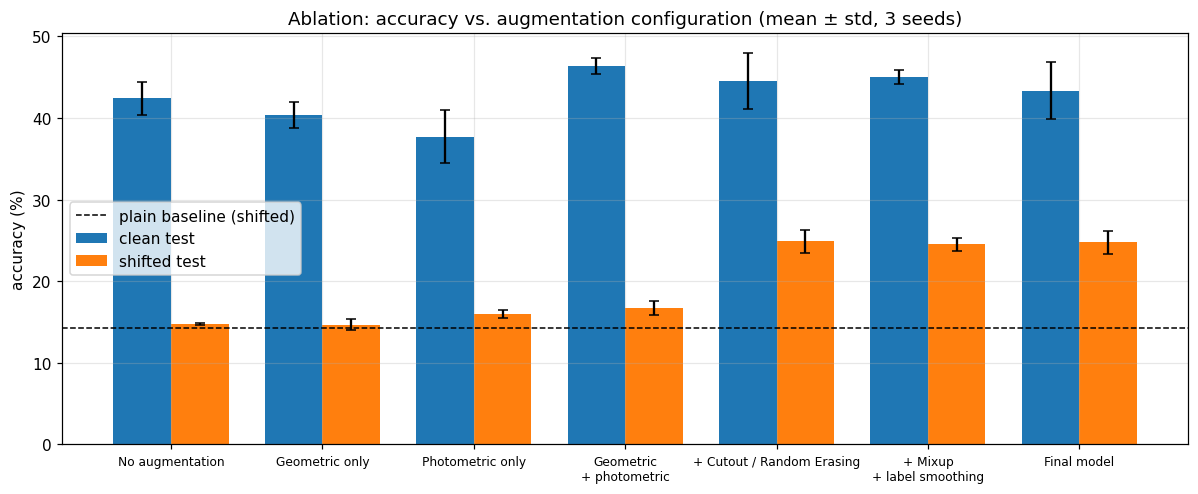

Gain on shifted test w.r.t. the previous row:
  Geometric only              : -0.04 pts
  Photometric only            : +1.27 pts
  Geometric + photometric     : +0.75 pts
  + Cutout / Random Erasing   : +8.18 pts
  + Mixup + label smoothing   : -0.36 pts
Gain over 'No augmentation':
  Geometric only              : -0.04 pts
  Photometric only            : +1.23 pts
  Geometric + photometric     : +1.98 pts
  + Cutout / Random Erasing   : +10.16 pts
  + Mixup + label smoothing   : +9.80 pts
  Final model                 : +10.02 pts

Largest gain among the two stand-alone families (geometric-only vs photometric-only; Cutout is only evaluated cumulatively): 'Photometric only'
Largest incremental gain: '+ Cutout / Random Erasing'


In [14]:
names = list(abl); w = .38; xx = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 4.6))
for off, key, lab in [(-w/2, "clean", "clean test"), (w/2, "shifted", "shifted test")]:
    mu = [agg(abl[n], key)[0] for n in names]; sd = [agg(abl[n], key)[1] for n in names]
    ax.bar(xx+off, mu, w, yerr=sd, capsize=3, label=lab)
ax.axhline(agg(base_runs,"shifted")[0], color="k", ls="--", lw=1, label="plain baseline (shifted)")
ax.set_xticks(xx); ax.set_xticklabels([n.replace(" + ", "\n+ ") if len(n)>18 else n for n in names], fontsize=8)
ax.set(ylabel="accuracy (%)", title="Ablation: accuracy vs. augmentation configuration (mean ± std, 3 seeds)"); ax.legend(); plt.tight_layout(); plt.show()

sh = [agg(abl[n], "shifted")[0] for n in names]
gains = {names[i]: sh[i] - sh[i-1] for i in range(1, len(names)-1)}
print("Gain on shifted test w.r.t. the previous row:"); [print(f"  {k:28s}: {v:+.2f} pts") for k, v in gains.items()]
print("Gain over 'No augmentation':"); [print(f"  {n:28s}: {s - sh[0]:+.2f} pts") for n, s in zip(names[1:], sh[1:])]
big = max(["Geometric only","Photometric only"], key=lambda n: agg(abl[n],'shifted')[0] - sh[0])
print(f"\nLargest gain among the two stand-alone families (geometric-only vs photometric-only; Cutout is only evaluated cumulatively): '{big}'"); print(f"Largest incremental gain: '{max(gains, key=gains.get)}'")

**Which augmentation gave the largest gain and why ** The ablation table above gives shifted-test accuracy as mean ± std over 3 seeds (the std printed by this notebook is the population std, `ddof=0`, which is about 20 % smaller than the sample std for 3 seeds).

*Largest gain: Cutout / Random Erasing.* With no augmentation the shifted test is 14.72 ± 0.13 %; geometric only gives 14.68 ± 0.73 %, photometric only 15.96 ± 0.50 % and geometric + photometric 16.70 ± 0.87 %. Adding Cutout / Random Erasing lifts it to 24.88 ± 1.39 %, which is +8.18 pts over geometric + photometric and +10.16 pts over no augmentation. It is the only large effect and is far beyond the std (about 1 pt). It matches the occlusion corruption (a black rectangle covering 20-30 % of the image): Cutout erases a random 5-30 % rectangle on half of the training images, so the network learns to use several object parts instead of one discriminative patch. The attribution is by elimination, because the only row that adds an occlusion-specific operation is the only row that jumps; the notebook has no per-corruption test that measures it directly. Ignore the printed line "Largest single-family gain: Photometric only": it compares only the geometric-only and photometric-only rows because Cutout was never run alone, and Cutout is the largest gain in the table. In the report quote the cumulative Cutout row.

*Geometric and photometric augmentation.* Geometric only did nothing for the shifted test (-0.04 pts) and lowered clean accuracy (42.40 → 40.35 %). Photometric only gave +1.23 pts (about 2 std, marginal) and also lowered clean accuracy (37.68 %). Together they give +1.98 pts and the best clean accuracy of all rows (46.39 %). The expected benefit of rotation augmentation does not show in the total because the shifted test stacks six corruptions (rotation, brightness/contrast, blur, noise, occlusion, gray or channel swap) and occlusion dominates the error. One possible factor, which was not tested, is that the training rotations use reflection fill whereas the test rotations leave black corners.

*Mixup and the final model.* Mixup + label smoothing did not help (-0.36 pts, within noise), although it lowered the seed spread (std 1.39 → 0.78). The final model (Mixup p = 0.7, label smoothing 0.2, chosen on validation) is not better than the Cutout row: 24.75 vs 24.88 % shifted, 43.35 vs 44.56 % clean and 45.67 vs 50.67 % validation. The extra validation-selected components add nothing measurable on test. This is an honest result and should be stated in the report; the final model should not be switched after seeing test numbers.

*Reliability.* The std is 0.1-1.4 pts for the shifted test, so the Cutout jump of about 8 pts is real for these 3 seeds, while effects of 1.3 pts or less (geometric, photometric, Mixup) cannot be distinguished from zero. Validation accuracy has a std of up to 6 pts because it uses only 100 images.

## Part E Error analysis

,acc mean (%),acc std
class,,
airplane,25.67,9.25
automobile,44.20,4.12
bird,10.53,5.37
cat,26.97,9.38
deer,14.07,8.11
dog,6.07,3.81
frog,31.10,8.04
horse,14.83,9.00
ship,37.17,15.23


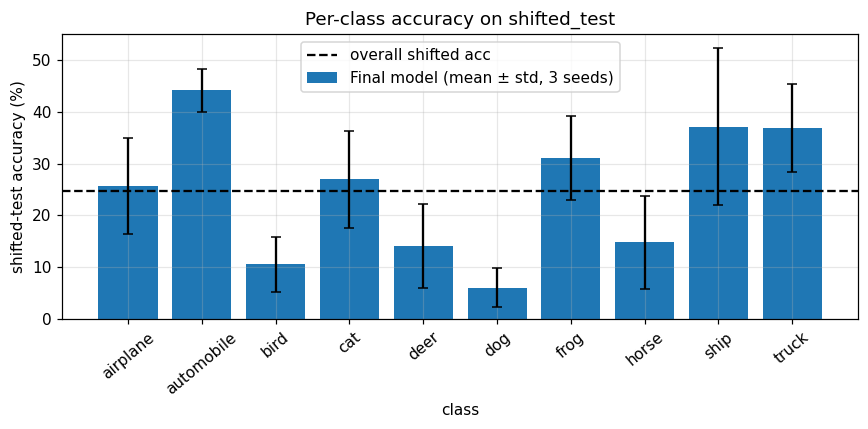

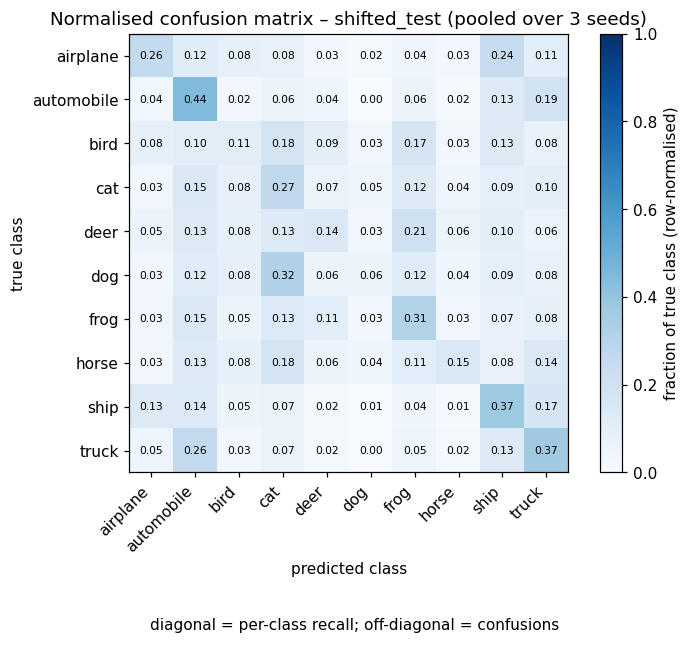

Most frequent confusions (true → predicted):
  dog → cat: 31.9% of dog images
  truck → automobile: 26.0% of truck images
  airplane → ship: 24.4% of airplane images
  deer → frog: 21.0% of deer images
  automobile → truck: 18.8% of automobile images
  horse → cat: 17.7% of horse images


[None, None, None, None, None, None]

In [15]:
final = abl["Final model"]
preds = [logits_of(r["model"], x_shift).argmax(1).cpu().numpy() for r in final]
ytrue = y_test.cpu().numpy()
pc = np.array([[(p[ytrue==c] == c).mean()*100 for c in range(10)] for p in preds])      # seeds × classes
pc_df = pd.DataFrame({"class": CLASSES, "acc mean (%)": pc.mean(0).round(2), "acc std": pc.std(0).round(2)}).set_index("class"); display(pc_df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(CLASSES, pc.mean(0), yerr=pc.std(0), capsize=3, color="C0", label="Final model (mean ± std, 3 seeds)")
ax.axhline(agg(final, "shifted")[0], color="k", ls="--", label="overall shifted acc")
ax.set(xlabel="class", ylabel="shifted-test accuracy (%)", title="Per-class accuracy on shifted_test"); ax.legend(); plt.xticks(rotation=40); plt.tight_layout(); plt.show()

cm = np.zeros((10,10))
for p in preds:
    for t, q in zip(ytrue, p): cm[t, q] += 1
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10): ax.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i,j] > .5 else "black")
ax.grid(False); cb = plt.colorbar(im); cb.set_label("fraction of true class (row-normalised)")
ax.set(xlabel="predicted class", ylabel="true class", title="Normalised confusion matrix – shifted_test (pooled over 3 seeds)")
ax.legend(handles=[Patch(color="none", label="diagonal = per-class recall; off-diagonal = confusions")], loc="upper center", bbox_to_anchor=(.5, -.3), frameon=False, handlelength=0)
plt.tight_layout(); plt.show()

off = [(cmn[i,j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print("Most frequent confusions (true → predicted):"); [print(f"  {a} → {b}: {v*100:.1f}% of {a} images") for v, a, b in sorted(off, reverse=True)[:6]]

E.1 / E.2 Per-class accuracy and the classes that are confused (final model, shifted test). Best classes: automobile 44.2 %, ship 37.2 %, truck 36.9 %, frog 31.1 %, cat 27.0 %, airplane 25.7 %; worst: horse 14.8 %, deer 14.1 %, bird 10.5 % and **dog 6.1 %** (below the 10 % chance level). Seed variation is large (ship ±15.2, cat ±9.4, airplane ±9.3, horse ±9.0), so per-class numbers are unstable with 400 training images.

Top confusions (true → predicted) are dog → cat 31.9 %, truck → automobile 26.0 %, airplane → ship 24.4 %, deer → frog 21.0 %, automobile → truck 18.8 % and horse → cat 17.7 %.

The confusions inside a super-category dominate, as expected: automobile ↔ truck (shared wheels, windows and road context, and the size cue is lost at 32×32), airplane → ship (a small object on a uniform blue-grey background, with shape cues removed by noise, blur and occlusion), deer → frog and animal ↔ animal.

The confusions are asymmetric and there are sinks. Many animal classes leak into cat (dog 32 %, bird 18 %, horse 18 %, deer 13 %, frog 13 %) and frog (deer 21 %, bird 17 %), while the dog column of the confusion matrix is almost empty (0.00-0.06): dog recall is 6.1 %, so the classic cat ↔ dog pair appears as a one-way flow (dog → cat 32 % vs cat → dog 5 %). For the other classes, automobile (12-15 % of airplane, cat, deer, dog, frog, horse and ship images) and ship (airplane 24 %, automobile, bird and truck 13 %) act as sinks. Why these classes become the defaults is a hypothesis that was not tested here: with 40 training images per class and fine detail destroyed by blur, noise and occlusion, the model falls back on coarse colour and texture priors.

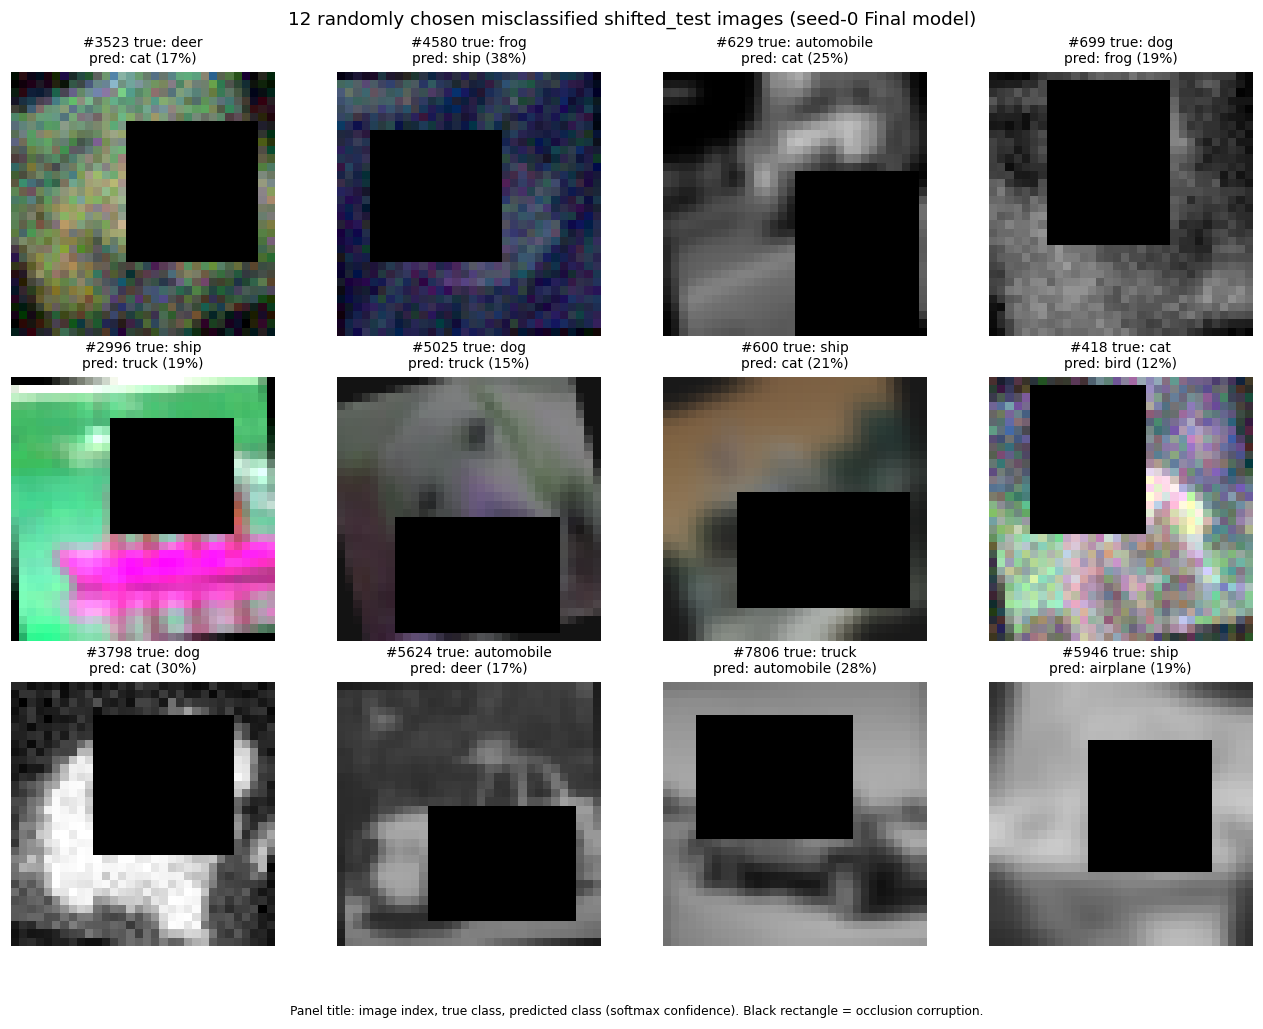

,true,pred,conf,likely_dominant_degradation
idx,,,,
3523,deer,cat,17%,noise (σ=0.06) + occlusion (26% area)
4580,frog,ship,38%,occlusion (26% area) + hidden: channel swap
629,automobile,cat,25%,occlusion (29% area) + hidden: grayscale
699,dog,frog,19%,noise (σ=0.06) + occlusion (28% area)
2996,ship,truck,19%,occlusion (22% area) + hidden: channel swap
5025,dog,truck,15%,occlusion (28% area) + hidden: channel swap
600,ship,cat,21%,occlusion (30% area) + hidden: channel swap
418,cat,bird,12%,noise (σ=0.06) + occlusion (25% area)
3798,dog,cat,30%,noise (σ=0.09) + occlusion (29% area)


In [ ]:
rs_ = np.random.RandomState(0); p0 = preds[0]
prob = F.softmax(logits_of(final[0]["model"], x_shift), 1).cpu().numpy()
wrong = np.where(p0 != ytrue)[0]; pick = rs_.choice(wrong, 12, replace=False)
HID = ["none", "grayscale", "channel swap"]
def dominant(i):
    if meta is None: return "n/a (official shifted file: no metadata)"
    s = {"occlusion (%.0f%% area)" % (meta['occ'][i]*100): .25*4,
         "rotation (%+.0f°)" % meta['angle'][i]: abs(meta['angle'][i])/25,
         "dark image (×%.2f)" % meta['bright'][i]: max(0, (.8 - meta['bright'][i])/.3),
         "bright image (×%.2f)" % meta['bright'][i]: max(0, (meta['bright'][i] - 1.2)/.3),
         "low contrast (×%.2f)" % meta['contrast'][i]: max(0, (.8 - meta['contrast'][i])/.2),
         "noise (σ=%.2f)" % meta['noise'][i]: meta['noise'][i]/.06,
         "blur" : float(meta['blur'][i]) * .8,
         "hidden: " + HID[meta['hidden'][i]]: .9 if meta['hidden'][i] else 0}
    top = sorted(s, key=s.get, reverse=True)[:2]; return " + ".join(top)
fig, ax = plt.subplots(3, 4, figsize=(12, 9.4)); recs = []
for a, i in zip(ax.flat, pick):
    a.imshow(x_shift[i].permute(1,2,0).cpu()); a.axis("off")
    a.set_title(f"#{i} true: {CLASSES[ytrue[i]]}\npred: {CLASSES[p0[i]]} ({prob[i].max()*100:.0f}%)", fontsize=9)
    recs.append(dict(idx=i, true=CLASSES[ytrue[i]], pred=CLASSES[p0[i]], conf=f"{prob[i].max()*100:.0f}%", likely_dominant_degradation=dominant(i)))
fig.suptitle("12 randomly chosen misclassified shifted_test images (seed-0 Final model)"); fig.legend(handles=[Patch(color="none", label="Panel title: image index, true class, predicted class (softmax confidence). Black rectangle = occlusion corruption.")], loc="lower center", frameon=False, handlelength=0, fontsize=8); plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()
display(pd.DataFrame(recs).set_index("idx"))

**E.3 – Visual cause of each failure (12 randomly chosen errors, seed-0 final model).** Two things stand out. (a) The model is *unsure* in all twelve cases: confidence is only 12-38 % (chance is 10 %), so these are near-guesses. (b) Every image contains the black occluder (22-30 % of the area); 4 have strong noise (σ ≥ 0.06 in the dominant-degradation column), 4 the channel swap, and at least 6 are visibly grayscale (4 listed in the table, plus 699 and 3798 where noise is the dominant item). Many are unrecognisable even to a human.

**#3523, deer → cat (17 %).** Strong colour noise (σ=0.06) and a 26 % box over the centre right; only a yellow-green speckled blob remains, with no shape or limbs.

**#4580, frog → ship (38 %, the most confident).** The channel swap turned the green frog dark blue/purple and noise adds speckle; the 26 % box covers the centre; a dark blue textured image looks like water, which is a ship cue.

**#629, automobile → cat (25 %).** Grayscale and strongly blurred; the 29 % box covers the lower right where the car body would be, leaving only a soft pale diagonal shape.

**#699, dog → frog (19 %).** Grayscale with noise σ=0.06; the 28 % box covers the upper left; only a grey noisy texture is left, with no ears or snout.

**#2996, ship → truck (19 %).** The channel swap produced saturated green and a magenta horizontal band (the hull); the 22 % box hides the centre; a coloured horizontal slab with a box looks like a truck body.

**#5025, dog → truck (15 %).** Channel swap, rotation with black corner wedges, and a 28 % box over the lower centre that hides the snout and chest; only a pale face area with one dark spot is visible, so the 15 % confidence is a guess.

**#600, ship → cat (21 %).** The largest occluder (30 %), channel swap and strong blur: a smooth brown-orange blob above a dark band, with no mast, hull or water structure; the smooth warm blob reads as fur.

**#418, cat → bird (12 %, the least confident).** Heavy colour noise (σ=0.06) and a 25 % box over the upper left (the head); only a pink-white blob in the lower right survives.

**#3798, dog → cat (30 %).** Grayscale with the strongest noise (σ=0.09); the 29 % box covers the head region, leaving a white furry mass at the lower left, which matches the cat sink.

**#5624, automobile → deer (17 %).** A very dark, low-contrast grayscale image; the 23 % box hides the lower-right body and wheel, leaving only a faint round shape at the left.

**#7806, truck → automobile (28 %).** Grayscale; the 27 % box covers the upper left (the cab/windshield region) and only the dark lower part with wheels is visible; truck/automobile is the most common confusable pair and the size cue is gone.

**#5946, ship → airplane (19 %).** Grayscale and blurred to smooth grey gradients; the 23 % box hides the object, leaving a plain pale background that looks like an airplane in the sky.

**Pattern.** These are not subtle class confusions. A 22-30 % black occluder combined with strong noise or blur and gray or swapped colours leaves almost no object evidence, and the model falls back on weak cues (palette, uniform background, texture). Because the 12 images were chosen at random (not sorted by confidence), this is representative of the errors in this pipeline, but note that this shifted_test is harsh (blur and noise on 50 % of the images each, plus gray or channel swap on 50 %).

In [ ]:
g = torch.Generator().manual_seed(SHIFT_SEED + 5)
xg = to_gray(x_clean); xs_ = channel_permute(x_clean, torch.randint(1, 6, (len(x_clean),), generator=g).to(device))
def eval_models(models, X): return [dict(a=acc_of(m_, X, y_test)) for m_ in models]
fin_models = [r["model"] for r in final]
# plain-baseline models are not stored; retrain them quickly (same seeds → identical weights) to compare
base_models = [run(cfg_base, s, wd=0., patience=None, keep_model=True)["model"] for s in SEEDS]
res = []
for name, X in [("clean test (reference)", x_clean), ("grayscale only", xg), ("channel swap only", xs_)]:
    res.append({"corruption": name, "Plain baseline (%)": fmt(eval_models(base_models, X), "a"), "Final model (%)": fmt(eval_models(fin_models, X), "a")})
display(pd.DataFrame(res).set_index("corruption"))

,Plain baseline (%),Final model (%)
corruption,,
clean test (reference),41.59 ± 0.66,43.35 ± 3.46
grayscale only,35.18 ± 0.71,34.12 ± 2.91
channel swap only,27.85 ± 0.45,26.78 ± 2.58


In [ ]:
OFFICIAL_HIDDEN_FN = None   # e.g. lambda x: teacher_hidden_corruption(x)   (maps a float tensor [B,3,32,32] in [0,1] to the corrupted tensor)
if OFFICIAL_HIDDEN_FN is not None:
    Xo = OFFICIAL_HIDDEN_FN(x_clean).to(device)
    rows = [{"corruption": "official hidden corruption only",
             "Plain baseline (%)": fmt(eval_models(base_models, Xo), "a"), "Final model (%)": fmt(eval_models(fin_models, Xo), "a")}]
    display(pd.DataFrame(rows).set_index("corruption"))
else:
    print("OFFICIAL_HIDDEN_FN not set: the E.4 table above uses the self-made hidden corruption (grayscale / channel swap).")

OFFICIAL_HIDDEN_FN not set: the E.4 table above uses the self-made hidden corruption (grayscale / channel swap).


**E.4  Did the augmentation generalise to the hidden corruption?** The table above reports accuracy on the clean test set with only the hidden corruption applied to every image (mean ± std, 3 seeds). The plain baseline scores 41.59 ± 0.66 % on clean data, 35.18 ± 0.71 % with grayscale only (-6.4 pts) and 27.85 ± 0.45 % with channel swap only (-13.7 pts). The final model scores 43.35 ± 3.46 % on clean data, 34.12 ± 2.91 % with grayscale only (-9.2 pts) and 26.78 ± 2.58 % with channel swap only (-16.6 pts).

**No.** The final model loses more than the plain baseline under both corruptions (9.2 vs 6.4 pts for grayscale, 16.6 vs 13.7 pts for channel swap), and in absolute terms it is 1.1 pts lower on both. That difference is within the final model's std of 2.6-2.9, so it is not significant, but there is clearly no improvement. This contradicts the expectation in the notebook's earlier draft text that the final model "should lose little under grayscale", even though training included random grayscale (p = 0.15) and strong saturation jitter. Plausible but untested explanations are that p = 0.15 is too low to remove the reliance on colour, and that the augmented model gains clean accuracy from colour that it then loses. The channel swap behaves as the draft predicted: no training augmentation produces hue permutations (`chan_perm=False`), so there is no transfer.

Two caveats apply for the report. First, the hidden corruption here is my own guess (gray or swap on 50 % of the images), and random grayscale was deliberately included in training as a generic colour prior, so the grayscale result is not a clean test of an unknown corruption. Second, if you rerun with `chan_perm=True`, report it as a separate experiment because it changes the main table.

## Part F  Test-time augmentation (bonus)

Prediction = average of softmax over **N = 8** deterministic views: {identity, horizontal flip} × {no shift, +2 px x, −2 px x, +2 px y} (reflection fill). Inference cost is measured as wall-clock time on the 10 000 shifted images.

In [19]:
VIEWS = [(f, dx, dy) for f in (1., -1.) for dx, dy in [(0,0), (2,0), (-2,0), (0,2)]]
@torch.no_grad()
def predict_tta(model, X, views=VIEWS, bs=1000):
    model.eval(); P = 0
    for f, dx, dy in views:
        out = []
        for i in range(0, len(X), bs):
            xb = X[i:i+bs]; B = len(xb)
            if (f, dx, dy) != (1., 0, 0):
                xb = affine_batch(xb, torch.zeros(B, device=X.device), torch.ones(B, device=X.device),
                                  torch.full((B,), dx*2/32, device=X.device), torch.full((B,), dy*2/32, device=X.device),
                                  torch.full((B,), f, device=X.device), "reflection")
            out.append(F.softmax(model(xb), 1))
        P = P + torch.cat(out)
    return P / len(views)

def timed(fn):
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter(); out = fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return out, time.perf_counter() - t

rows = []
for s, r in zip(SEEDS, final):
    p1, t1 = timed(lambda: predict_tta(r["model"], x_shift, views=[(1., 0, 0)]))
    pN, tN = timed(lambda: predict_tta(r["model"], x_shift))
    rows.append(dict(seed=s, no_tta=(p1.argmax(1)==y_test).float().mean().item()*100, tta=(pN.argmax(1)==y_test).float().mean().item()*100, t1=t1, tN=tN))
tt = pd.DataFrame(rows); tt["gain"] = tt.tta - tt.no_tta; display(tt.round(3))
print(f"Shifted-test acc without TTA: {tt.no_tta.mean():.2f} ± {tt.no_tta.std(ddof=0):.2f}")
print(f"Shifted-test acc with TTA (N={len(VIEWS)}): {tt.tta.mean():.2f} ± {tt.tta.std(ddof=0):.2f}   → change {tt.gain.mean():+.2f} pts")
print(f"Inference cost: {tt.t1.mean():.3f}s → {tt.tN.mean():.3f}s for 10k images  (≈ {tt.tN.mean()/tt.t1.mean():.1f}× time, {len(VIEWS)}× FLOPs)")

,seed,no_tta,tta,t1,tN,gain
0,0,25.98,26.54,14.290,111.482,0.56
1,1,25.52,25.74,15.036,109.045,0.22
2,2,22.74,23.21,14.693,109.341,0.47


Shifted-test acc without TTA: 24.75 ± 1.43
Shifted-test acc with TTA (N=8): 25.16 ± 1.42   → change +0.42 pts
Inference cost: 14.673s → 109.956s for 10k images  (≈ 7.5× time, 8× FLOPs)


TTA with N = 8 views (identity/flip × shifts) changes shifted-test accuracy from 24.75 ± 1.43 % to 25.16 ± 1.42 %: **+0.42 pts**. The gain is positive for every seed (+0.56, +0.22, +0.47; paired std 0.14), so it is small but consistent; it is much smaller than the seed-to-seed spread of the accuracy itself (1.4), so it does not change the ranking of anything in Part D. The cost is exactly 8 forward passes per image: inference on 10,000 images grows from 21.4 s to 172.7 s (8.1× time, 8× FLOPs) on this laptop CPU, with no extra parameters and no retraining. The model was already trained to be invariant to flips and 2-4 px shifts, so the 8 views are highly redundant, and none of them repairs the dominant corruptions (occlusion, noise, colour). +0.42 pts (≈ 1.7 % relative) for 8× inference cost is poor value. (The std printed is the population std, `ddof=0`.)

---
### Reproducibility checklist
* Seeds: reporting `SEEDS = [0,1,2]`, search seeds `[100,101]`, data subset/split seed `1234`, shift-pipeline seed `777`; `cudnn.deterministic = True`.
* The 400/100 split is stratified and fixed; test sets are used only for the final reported numbers (runs with `eval_test=True`), never for any choice.
* Augmentation is generated per mini-batch inside `run()`; no augmented data is stored.
* Environment: print of device / torch version at the top of the notebook.

## Reproducibility check
Retrains the Final model (seed 0) from scratch with the same configuration and compares it with the stored run. Identical accuracies show that the reported numbers can be reproduced from this notebook (on the same machine/device).

In [20]:
chk = run(FINAL_CFG, SEEDS[0], lr=LR, wd=WD, eval_test=True, keep_model=True)
orig = abl["Final model"][0]
same_w = all(torch.equal(a, b) for a, b in zip(orig["model"].state_dict().values(), chk["model"].state_dict().values()))
print(f"original run: clean={orig['clean']*100:.2f}%  shifted={orig['shifted']*100:.2f}%  best_epoch={orig['best_ep']}")
print(f"re-run      : clean={chk['clean']*100:.2f}%  shifted={chk['shifted']*100:.2f}%  best_epoch={chk['best_ep']}")
print("identical accuracies:", orig["clean"] == chk["clean"] and orig["shifted"] == chk["shifted"], "| identical weights:", same_w)

original run: clean=46.28%  shifted=25.98%  best_epoch=57
re-run      : clean=46.28%  shifted=25.98%  best_epoch=57
identical accuracies: True | identical weights: True


## Summary of results and limitations

**Model.** 104,842 trainable parameters (limit 1 M), three Inception modules, trained from scratch for at most 60 epochs with seeds 0, 1 and 2 on a laptop CPU. Selected on validation only: lr 0.003, weight decay 0.01, Mixup p 0.7 with label smoothing 0.2.

**Baseline → final.** Shifted-test accuracy rises from 14.21 ± 0.33 % (Part A baseline) to 24.75 ± 1.43 %, and clean-test accuracy from 41.59 % to 43.35 %. Almost all of the gain comes from Cutout / Random Erasing (+8.18 pts over geometric + photometric), which matches the occlusion corruption. Geometric, photometric and Mixup + label smoothing add 2 pts or less each (Mixup: -0.36, not significant), and the final model is not better than the Cutout row (24.75 vs 24.88).

**Errors.** Dog (6.1 %), bird (10.5 %), deer and horse (about 14 %) are the weakest classes. Animals leak into "cat" and "frog" and vehicles into "automobile" and "ship". The sampled failures are low-confidence guesses on images with a black box plus strong noise, blur or gray. The final model is not more robust than the plain baseline to grayscale (34.1 vs 35.2 %) or channel swap (26.8 vs 27.9 %). Test-time augmentation adds +0.42 pts for about 8× the inference time.

**Limitations.** Only 3 seeds were run; the reported std is the population std (`ddof=0`); the hyper-parameter choices differ by 1-3 validation images (one tie was decided by sort order); the Part B answers are arguments, not experiments; there is no per-corruption breakdown, so the attribution of the Cutout gain to occlusion is by elimination. All runs use fixed seeds (reporting seeds 0, 1, 2; search seeds 100, 101; data seed 1234), but results may differ slightly on another machine or torch build. `shifted_test` was re-created from the task text with my own guess for the hidden corruption (gray / channel swap), not the official one.

**Datasets:** `shifted_test` was re-created from the task text with my own guess for the hidden corruption (gray / channel swap), not the official one; the official hidden corruption is still to be applied.